In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

### Load results

In [33]:
df = pd.read_csv("results/experiments.csv")
df.shape

(63000, 13)

### Average and standard deviation across seeds

In [34]:
group_cols = ["work_num", "validator_num", "env", "algorithm", "k"]
col_metric = ["Pd", "FAR", "FRR"]

summary = df.groupby(group_cols)[col_metric].agg(["mean", "std"]) # groups the csv by shared config and gives mean and standard dev (section 16)
summary

Pd                 FAR  \
                                                     mean       std      mean   
work_num validator_num env          algorithm k                                 
200      300           Semi-Trusted majority  3  0.896062  0.003398  0.103938   
                                              5  0.942101  0.002749  0.057899   
                                              7  0.966660  0.002066  0.033340   
                                    single    1  0.800112  0.003756  0.199888   
                                    weighted  3  0.896062  0.003398  0.103938   
...                                                   ...       ...       ...   
400      100           Untrusted    majority  7  0.710022  0.010924  0.289978   
                                    single    1  0.599878  0.005756  0.400122   
                                    weighted  3  0.647838  0.008127  0.352162   
                                              5  0.682425  0.009747  0.317575   
                                              7  0.710023  0.010924  0.289977   

                                                                FRR            
                                                      std      mean       std  
work_num validator_num env          algorithm k                                
200      300           Semi-Trusted majority  3  0.003398  0.103900  0.003310  
                                              5  0.002749  0.057832  0.002650  
                                              7  0.002066  0.033287  0.001974  
                                    single    1  0.003756  0.199908  0.003483  
                                    weighted  3  0.003398  0.103900  0.003310  
...                                                   ...       ...       ...  
400      100           Untrusted    majority  7  0.010924  0.289955  0.010903  
                                    single    1  0.005756  0.400129  0.005702  
                                    weighted  3  0.008127  0.352106  0.008151  
                                              5  0.009747  0.317569  0.009719  
                                              7  0.010924  0.289955  0.010902  

[63 rows x 6 columns]


### Probability of Detection vs Validators per Task

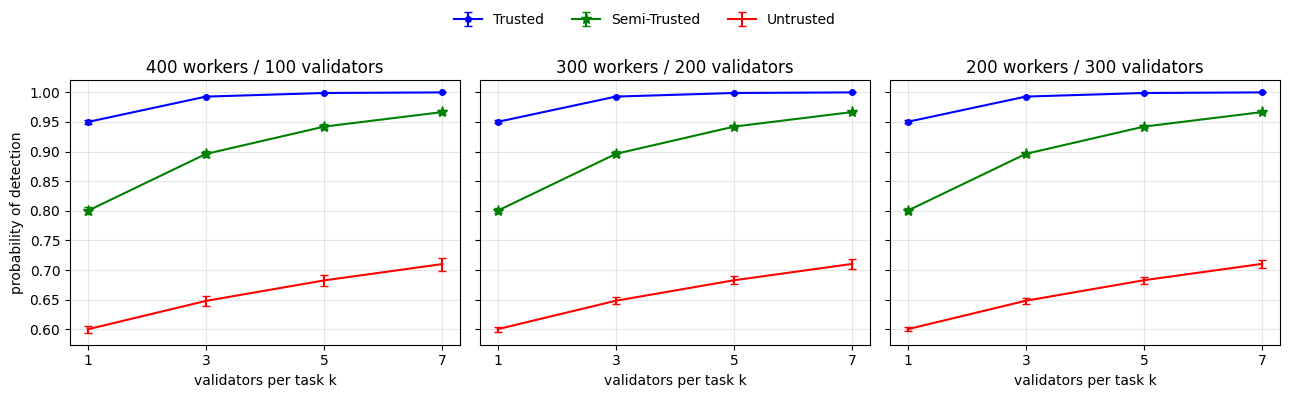

In [41]:
env_colors = {"Trusted": ("Blue", "."), "Semi-Trusted": ("Green", "*"), "Untrusted": ("Red", ",")}
graph1 = df[(df["algorithm"] == "single") | (df["algorithm"] == "majority")] # single and majority algos

fig, axes = plt.subplots(1, 3, figsize=(13,4), sharey=True)

for ax, (work_num, validator_num) in zip(axes, [(400, 100), (300, 200), (200,300)]):
    scenario = graph1[graph1["validator_num"]==validator_num]

    for env, (color, marker) in env_colors.items():
        env_rows = scenario[scenario["env"]==env]
        stats=env_rows.groupby("k")["Pd"].agg(["mean", "std"])

        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], color=color, marker=marker, markersize=8, capsize=3, label=env)

    ax.set_title(f"{work_num} workers / {validator_num} validators")

    ax.set_xlabel("validators per task k")

    ax.set_xticks([1,3,5, 7])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("probability of detection")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)

plt.tight_layout(rect=[0,0,1,0.9])

plt.show()

### Probability of Detection vs Total Validator Population

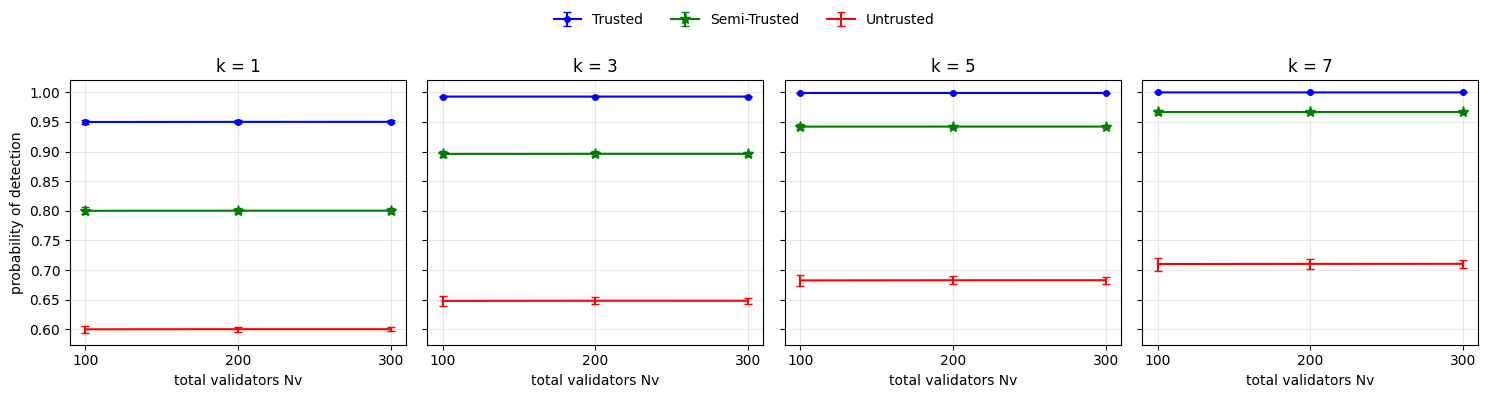

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(15,4), sharey=True)

for ax,k in zip(axes, config.K_VALUES):
    k_rows = graph1[graph1["k"]==k]

    for env, (color, marker) in env_colors.items():
        env_rows = k_rows[k_rows["env"]== env]

        stats = env_rows.groupby("validator_num")["Pd"].agg(["mean", "std"])

        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], color=color, marker=marker, markersize=8, capsize=3, label=env)

    ax.set_title(f"k = {k}")
    ax.set_xlabel("total validators Nv")
    ax.set_xticks([100, 200, 300])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("probability of detection")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)

plt.tight_layout(rect=[0,0,1,0.9])
plt.show()